In [1]:
# PRITHA NAGPAL 23BDS0154 (ASSESSMENT-10)

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

In [27]:
import os
from pathlib import Path

DATA_DIR = Path.home() / "Downloads" / "RiceDiseaseDataset_yolo_test"

IMAGE_DIR = DATA_DIR / "images"
LABEL_DIR = DATA_DIR / "labels"

print("Dataset exists:", DATA_DIR.exists())
print("Images folder exists:", IMAGE_DIR.exists())
print("Labels folder exists:", LABEL_DIR.exists())

image_files = []
for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]:
    image_files.extend(IMAGE_DIR.glob(ext))

label_files = list(LABEL_DIR.glob("*.txt"))

print("\nNumber of images:", len(image_files))
print("Number of annotation files:", len(label_files))

print("\nYAML FILE:")
print((DATA_DIR / "rice_detection.yaml").read_text())

Dataset exists: True
Images folder exists: True
Labels folder exists: True

Number of images: 0
Number of annotation files: 0

YAML FILE:
                                                                                                                                                                                                       


In [28]:
%pip install tensorflow scikit-learn pandas matplotlib seaborn pillow pyyaml 

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [32]:
import yaml

yaml_path = DATA_DIR / "rice_detection.yaml"

with open(yaml_path, "rb") as f:
    raw = f.read()

# Decode while ignoring malformed bytes
if raw.startswith(b"\xfe\xff"):
    yaml_text = raw.decode("utf-16-be", errors="ignore")
else:
    yaml_text = raw.decode("utf-16-le", errors="ignore")

yaml_text = yaml_text.replace("\x00", "").strip()

print("YAML CONTENT:")
print(repr(yaml_text[:1000]))

config = yaml.safe_load(yaml_text)

print("\nYAML loaded successfully!")
print(config)

YAML CONTENT:
''

YAML loaded successfully!
None


In [36]:
from pathlib import Path
import os

print("1. DATASET FILES")

for file in DATA_DIR.iterdir():
    print(file.name, "| Size:", file.stat().st_size, "bytes")

print("\n2. YAML FILE CONTENTS")

for filename in ["rice_detection.yaml", "yolov5x.yaml"]:
    path = DATA_DIR / filename
    print("\n", filename)

    if path.exists():
        raw = path.read_bytes()
        print("Size:", len(raw))
        print("First 200 bytes:", repr(raw[:200]))

print("\n3. SAMPLE YOLO ANNOTATIONS")

for file in list(LABEL_DIR.glob("*.txt"))[:5]:
    print("\n", file.name)
    print(file.read_text(errors="replace")[:500])

print("\n4. IMAGE COUNT:", len(image_files))
print("5. LABEL COUNT:", len(label_files))


1. DATASET FILES
images | Size: 160 bytes
labels | Size: 224 bytes
rice_detection.yaml | Size: 199 bytes
yolov5x.yaml | Size: 1582 bytes

2. YAML FILE CONTENTS

 rice_detection.yaml
Size: 199
First 200 bytes: b'\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\

In [40]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path.home() / "Downloads" / "RiceDiseaseDataset_yolo_test"

def get_disease(filename):
    name = filename.lower()

    if "blb" in name or "blight" in name:
        return "Bacterial_Leaf_Blight"
    elif "brown" in name:
        return "Brown_Spot"
    elif "blast" in name:
        return "Rice_Blast"
    else:
        return None

datasets = {}

for split in ["train", "valid", "test"]:
    records = []

    img_dir = DATA_DIR / "images" / split

    for img in img_dir.iterdir():
        if img.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            disease = get_disease(img.name)

            if disease:
                records.append({
                    "Image_Path": str(img),
                    "Disease": disease
                })

    datasets[split] = pd.DataFrame(records)

    print(f"\n{split.upper()}")
    print(datasets[split]["Disease"].value_counts())
    print("Total:", len(datasets[split]))

train_df = datasets["train"]
valid_df = datasets["valid"]
test_df = datasets["test"]

print("\nUnknown/unlabelled images:")
for split in ["train", "valid", "test"]:
    print(split, ":", sum(
        get_disease(p.name) is None
        for p in (DATA_DIR / "images" / split).iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ))


TRAIN
Disease
Bacterial_Leaf_Blight    269
Brown_Spot               145
Rice_Blast               132
Name: count, dtype: int64
Total: 546

VALID
Disease
Bacterial_Leaf_Blight    70
Brown_Spot               44
Rice_Blast               37
Name: count, dtype: int64
Total: 151

TEST
Disease
Bacterial_Leaf_Blight    47
Brown_Spot               29
Rice_Blast               25
Name: count, dtype: int64
Total: 101

Unknown/unlabelled images:
train : 37
valid : 9
test : 6


In [57]:
from PIL import Image, ImageOps
import numpy as np
import tensorflow as tf

IMG_SIZE = 128
BATCH_SIZE = 16

def prepare_data(dataframe):
    X, y = [], []
    skipped = []

    for _, row in dataframe.iterrows():
        try:
            img = Image.open(row["Image_Path"])
            img = ImageOps.exif_transpose(img).convert("RGB")
            img = img.resize((IMG_SIZE, IMG_SIZE))

            X.append(np.asarray(img, dtype=np.uint8))
            y.append(label_map[row["Disease"]])

        except Exception as e:
            skipped.append(row["Image_Path"])

    X = np.array(X, dtype=np.uint8)
    y = np.array(y, dtype=np.int32)

    print("Valid images:", len(X))
    print("Skipped images:", len(skipped))

    if skipped:
        print("Skipped files:")
        for path in skipped:
            print(path)

    return X, y

X_train, y_train = prepare_data(train_df)
X_valid, y_valid = prepare_data(valid_df)
X_test, y_test = prepare_data(test_df)

Valid images: 546
Skipped images: 0
Valid images: 6
Skipped images: 145
Skipped files:
/Users/prithanagpal/Downloads/RiceDiseaseDataset_yolo_test/images/valid/rice-blast-16.jpeg
/Users/prithanagpal/Downloads/RiceDiseaseDataset_yolo_test/images/valid/brownspot_orig_029.jpg
/Users/prithanagpal/Downloads/RiceDiseaseDataset_yolo_test/images/valid/brownspot_orig_001.jpg
/Users/prithanagpal/Downloads/RiceDiseaseDataset_yolo_test/images/valid/brownspot_orig_015.jpg
/Users/prithanagpal/Downloads/RiceDiseaseDataset_yolo_test/images/valid/img_brown_162.jpg
/Users/prithanagpal/Downloads/RiceDiseaseDataset_yolo_test/images/valid/brownspot_orig_014.jpg
/Users/prithanagpal/Downloads/RiceDiseaseDataset_yolo_test/images/valid/brownspot_orig_028.jpg
/Users/prithanagpal/Downloads/RiceDiseaseDataset_yolo_test/images/valid/blight_rotated_042.jpg
/Users/prithanagpal/Downloads/RiceDiseaseDataset_yolo_test/images/valid/blight_rotated_056.jpg
/Users/prithanagpal/Downloads/RiceDiseaseDataset_yolo_test/images/v

In [45]:
def make_tf_dataset(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))

    ds = ds.map(
        lambda image, label: (
            tf.cast(image, tf.float32) / 255.0,
            label
        )
    )

    if training:
        ds = ds.shuffle(len(X), seed=42)

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_tf_dataset(X_train, y_train, True)
valid_ds = make_tf_dataset(X_valid, y_valid)
test_ds = make_tf_dataset(X_test, y_test)

print("All datasets prepared successfully!")

Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: [Errno 28] No space left on device
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: [Errno 28] No space left on device
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: [Errno 28] No space left on device
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOG

In [46]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(3),
    y=y_train
)

class_weights = dict(enumerate(class_weights))

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True
        )
    ]
)

Epoch 1/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.5403 - loss: 0.9409 - val_accuracy: 0.8333 - val_loss: 0.9350
Epoch 2/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.5476 - loss: 0.8745 - val_accuracy: 0.3333 - val_loss: 1.7098
Epoch 3/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.5934 - loss: 0.8820 - val_accuracy: 0.5000 - val_loss: 1.1633
Epoch 4/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.6886 - loss: 0.7259 - val_accuracy: 0.6667 - val_loss: 0.7799
Epoch 5/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - accuracy: 0.7527 - loss: 0.5862 - val_accuracy: 0.5000 - val_loss: 0.8336
Epoch 6/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.7637 - loss: 0.5171 - val_accuracy: 0.5000 - val_loss: 1.4442
Epoch 7/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - accuracy: 0.8205 - loss: 0.4383 - val_accuracy: 0.8333 - val_loss: 0.5587
Epoch 8/20
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - accuracy: 0.8462 - loss: 0.3585 - val_accuracy: 0.6667 - v

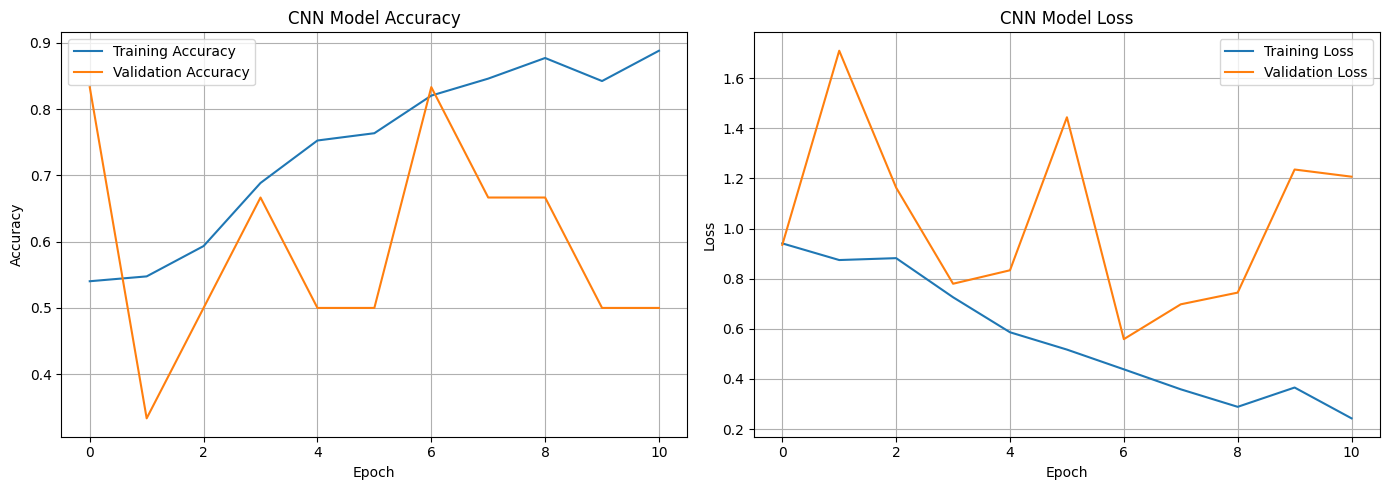

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print("TEST ACCURACY:", round(accuracy_score(y_test, y_pred), 4))
print("PRECISION:", round(precision_score(y_test, y_pred, average="weighted", zero_division=0), 4))
print("RECALL:", round(recall_score(y_test, y_pred, average="weighted", zero_division=0), 4))
print("F1 SCORE:", round(f1_score(y_test, y_pred, average="weighted", zero_division=0), 4))

print("\nCLASSIFICATION REPORT:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    zero_division=0
))


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
TEST ACCURACY: 0.6931
PRECISION: 0.7063
RECALL: 0.6931
F1 SCORE: 0.686

CLASSIFICATION REPORT:

                       precision    recall  f1-score   support

Bacterial_Leaf_Blight       0.66      0.85      0.74        47
           Brown_Spot       0.76      0.55      0.64        29
           Rice_Blast       0.74      0.56      0.64        25

             accuracy                           0.69       101
            macro avg       0.72      0.65      0.67       101
         weighted avg       0.71      0.69      0.69       101



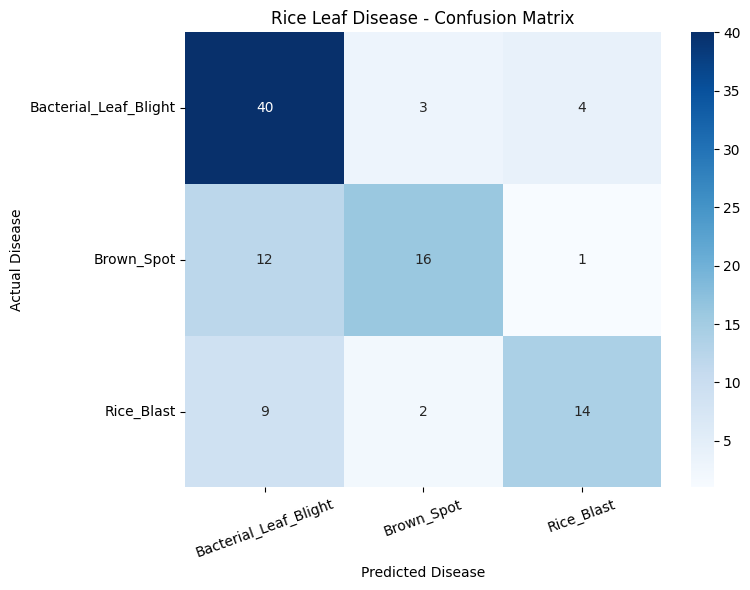

In [49]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Rice Leaf Disease - Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.xticks(rotation=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

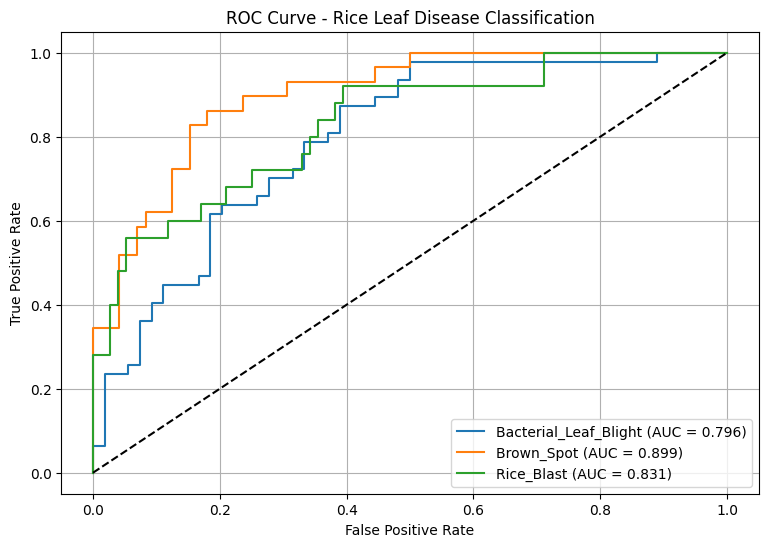

AUC scores:
Bacterial_Leaf_Blight : 0.7955
Brown_Spot : 0.8989
Rice_Blast : 0.8305


In [50]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

y_test_binary = label_binarize(y_test, classes=[0, 1, 2])

plt.figure(figsize=(9, 6))

for i, disease in enumerate(CLASS_NAMES):

    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        y_prob[:, i]
    )

    auc_score = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{disease} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Rice Leaf Disease Classification")
plt.legend()
plt.grid()
plt.show()

print("AUC scores:")
for i, disease in enumerate(CLASS_NAMES):
    print(
        disease,
        ":",
        round(roc_auc_score(y_test_binary[:, i], y_prob[:, i]), 4)
    )

Total misclassified images: 31


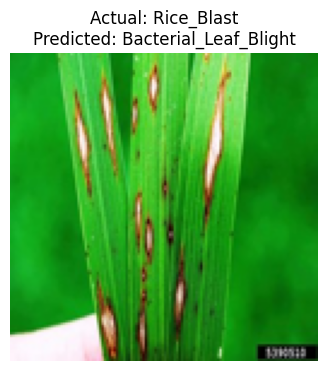

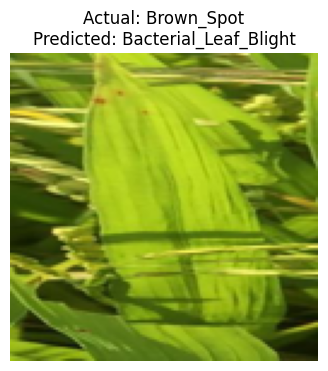

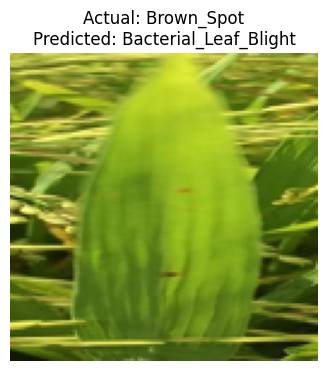

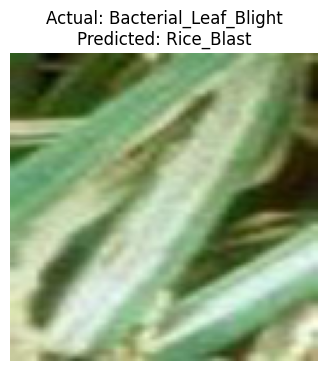

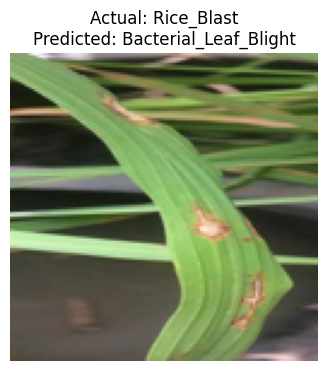

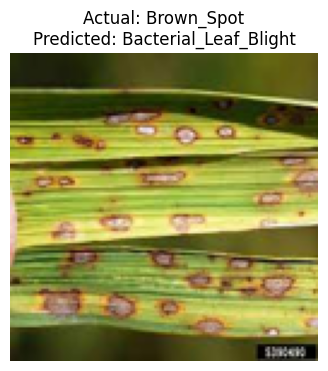

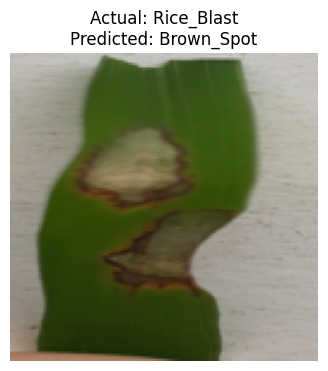

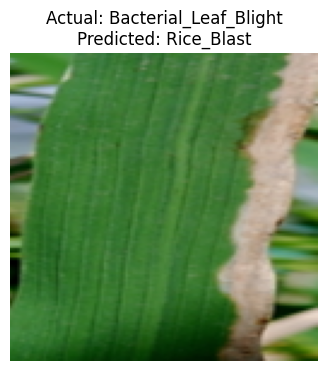

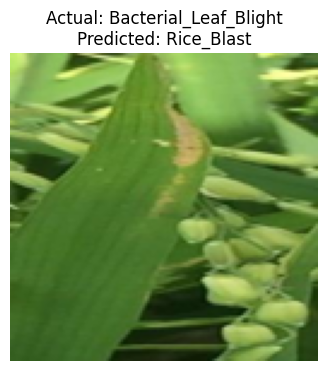

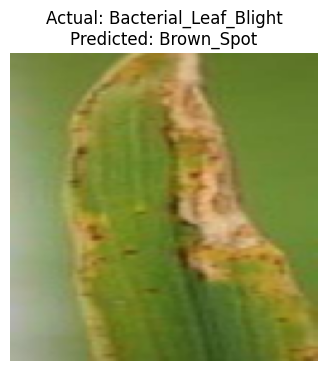

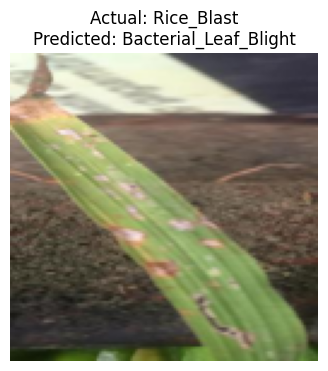

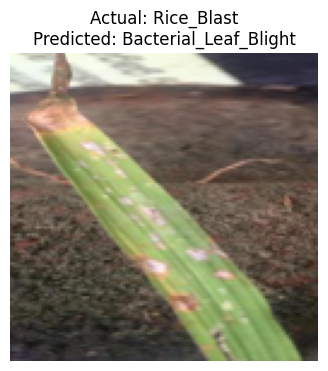

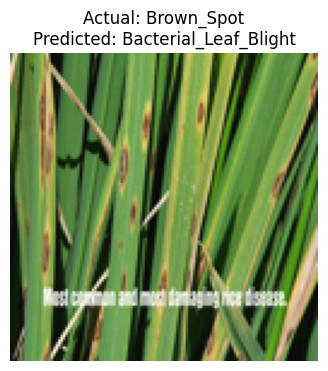

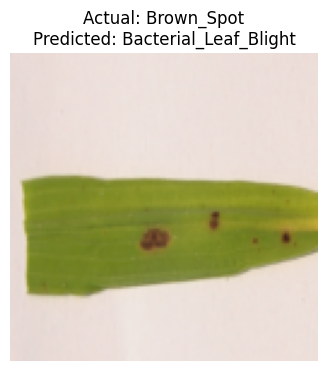

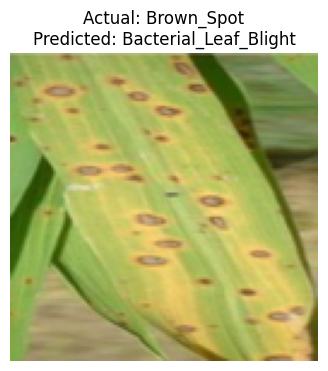

In [51]:
wrong_indices = np.where(y_test != y_pred)[0]

print("Total misclassified images:", len(wrong_indices))

for i in wrong_indices[:15]:

    plt.figure(figsize=(5, 4))

    plt.imshow(X_test[i])

    plt.title(
        f"Actual: {CLASS_NAMES[y_test[i]]}\n"
        f"Predicted: {CLASS_NAMES[y_pred[i]]}"
    )

    plt.axis("off")
    plt.show()

In [52]:
from collections import defaultdict

errors = defaultdict(int)
totals = defaultdict(int)

for actual, predicted in zip(y_test, y_pred):
    disease = CLASS_NAMES[actual]
    totals[disease] += 1

    if actual != predicted:
        errors[disease] += 1

print("DISEASE-WISE ERROR ANALYSIS\n")

for disease in CLASS_NAMES:
    error_count = errors[disease]
    total = totals[disease]

    error_rate = (error_count / total) * 100 if total else 0

    print(f"{disease}")
    print("Total test images:", total)
    print("Misclassified:", error_count)
    print("Error rate:", round(error_rate, 2), "%")
    print()

DISEASE-WISE ERROR ANALYSIS

Bacterial_Leaf_Blight
Total test images: 47
Misclassified: 7
Error rate: 14.89 %

Brown_Spot
Total test images: 29
Misclassified: 13
Error rate: 44.83 %

Rice_Blast
Total test images: 25
Misclassified: 11
Error rate: 44.0 %



In [55]:
model.save("rice_leaf_disease_cnn.keras")

print("CNN model saved successfully!")

CNN model saved successfully!


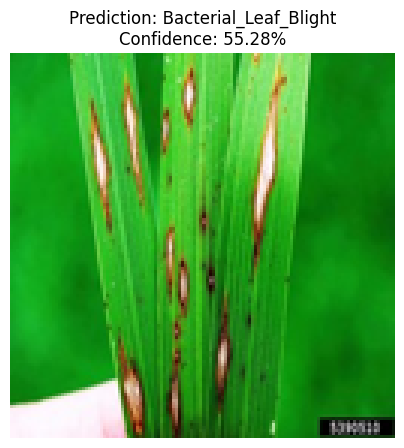

('Bacterial_Leaf_Blight', np.float32(55.277016))

In [56]:
from PIL import Image

def predict_rice_disease(image_path):

    img = Image.open(image_path).convert("RGB")
    img = img.resize((128, 128))

    arr = np.array(img, dtype=np.float32) / 255.0
    arr = np.expand_dims(arr, axis=0)

    prediction = model.predict(arr, verbose=0)[0]

    predicted_class = CLASS_NAMES[np.argmax(prediction)]
    confidence = np.max(prediction) * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.axis("off")
    plt.show()

    return predicted_class, confidence

# Replace with an actual image path
predict_rice_disease(str(test_df.iloc[0]["Image_Path"]))